In [55]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn import linear_model
from sklearn.linear_model import RidgeClassifier
from sklearn.model_selection import train_test_split

In [98]:
from sklearn.datasets import load_breast_cancer
X, y = load_breast_cancer(return_X_y=True)
y

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0,
       0, 0, 1, 0, 1, 1, 1, 1, 1, 0, 0, 1, 0, 0, 1, 1, 1, 1, 0, 1, 0, 0,
       1, 1, 1, 1, 0, 1, 0, 0, 1, 0, 1, 0, 0, 1, 1, 1, 0, 0, 1, 0, 0, 0,
       1, 1, 1, 0, 1, 1, 0, 0, 1, 1, 1, 0, 0, 1, 1, 1, 1, 0, 1, 1, 0, 1,
       1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 1, 0, 0, 1, 1, 1, 0, 0, 1, 0, 1, 0,
       0, 1, 0, 0, 1, 1, 0, 1, 1, 0, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 0, 1, 1, 1, 1, 0, 0, 1, 0, 1, 1, 0, 0, 1, 1, 0, 0, 1, 1, 1,
       1, 0, 1, 1, 0, 0, 0, 1, 0, 1, 0, 1, 1, 1, 0, 1, 1, 0, 0, 1, 0, 0,
       0, 0, 1, 0, 0, 0, 1, 0, 1, 0, 1, 1, 0, 1, 0, 0, 0, 0, 1, 1, 0, 0,
       1, 1, 1, 0, 1, 1, 1, 1, 1, 0, 0, 1, 1, 0, 1, 1, 0, 0, 1, 0, 1, 1,
       1, 1, 0, 1, 1, 1, 1, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 1, 1, 1, 1, 1, 1, 0, 1, 0, 1, 1, 0, 1, 1, 0, 1, 0, 0, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 0,

In [64]:
df_EPA = pd.read_csv('/Users/siobhankassem/Desktop/USC/Classes/Fall 2026/Python Data Science/Datasets/LA_AQS_2023.csv') 

In [65]:
df_EPA.head()

,State Code,County Code,Site Number,Parameter Code,POC,Latitude,Longitude,Datum,Parameter Name,Duration Description,...,AQI,Daily Criteria Indicator,Tribe Name,State Name,County Name,City Name,Local Site Name,Address,MSA or CBSA Name,Data Source
0,6,37,1103,68103,1,34.06659,-118.22688,WGS84,Ambient Min Temperature,24 HOUR,...,.,Y,NaN,California,Los Angeles,Los Angeles,Los Angeles-North Main Street,"1630 N MAIN ST, LOS ANGELES","Los Angeles-Long Beach-Anaheim, CA",AQS Data Mart
1,6,37,1103,42602,3,34.06659,-118.22688,WGS84,Nitrogen dioxide (NO2),1 HOUR,...,16,Y,NaN,California,Los Angeles,Los Angeles,Los Angeles-North Main Street,"1630 N MAIN ST, LOS ANGELES","Los Angeles-Long Beach-Anaheim, CA",AQS Data Mart
2,6,37,1103,62201,1,34.06659,-118.22688,WGS84,Relative Humidity,1 HOUR,...,.,Y,NaN,California,Los Angeles,Los Angeles,Los Angeles-North Main Street,"1630 N MAIN ST, LOS ANGELES","Los Angeles-Long Beach-Anaheim, CA",AQS Data Mart
3,6,37,1103,62101,1,34.06659,-118.22688,WGS84,Outdoor Temperature,1 HOUR,...,.,Y,NaN,California,Los Angeles,Los Angeles,Los Angeles-North Main Street,"1630 N MAIN ST, LOS ANGELES","Los Angeles-Long Beach-Anaheim, CA",AQS Data Mart
4,6,37,1103,42603,1,34.06659,-118.22688,WGS84,Oxides of nitrogen (NOx),1 HOUR,...,.,Y,NaN,California,Los Angeles,Los Angeles,Los Angeles-North Main Street,"1630 N MAIN ST, LOS ANGELES","Los Angeles-Long Beach-Anaheim, CA",AQS Data Mart


In [66]:
df_EPA['Parameter Name'].unique()

<StringArray>
[   'Ambient Min Temperature',     'Nitrogen dioxide (NO2)',
          'Relative Humidity',        'Outdoor Temperature',
   'Oxides of nitrogen (NOx)',    'Wind Direction - Scalar',
   'Sample Min Baro Pressure', 'Wind Direction - Resultant',
   'Sample Max Baro Pressure',        'Elapsed Sample Time',
 ...
             'Iron (TSP) STP',        'Strontium (TSP) STP',
               'Acetaldehyde',               'Formaldehyde',
        'Methyl ethyl ketone',       'Molybdenum (TSP) STP',
        'Beryllium (TSP) STP',            'Propionaldehyde',
              'Butyraldehyde',              'Hexanaldehyde']
Length: 164, dtype: str

In [67]:
O3 = df_EPA[(df_EPA['Parameter Name'] == 'Ozone') & (df_EPA['Duration Description']=='1 HOUR')]
NO2 = df_EPA[(df_EPA['Parameter Name'] == 'Nitrogen dioxide (NO2)') & (df_EPA['Duration Description']=='1 HOUR')]
PM = df_EPA[(df_EPA['Parameter Name'] == 'PM2.5 - Local Conditions') & (df_EPA['Duration Description']=='1 HOUR')]

O3_conc = pd.DataFrame(data = {"O3" : O3['Arithmetic Mean'], 'date' : O3['Date (Local)']})
NO2_conc = pd.DataFrame(data = {"NO2" : NO2['Arithmetic Mean'], 'date' : NO2['Date (Local)']})
PM_conc = pd.DataFrame(data = {"PM" : PM['Arithmetic Mean'], 'date' : PM['Date (Local)']})

conc_all = O3_conc.merge(NO2_conc,  on=['date'])
conc_all = conc_all.merge(PM_conc, on='date')

In [68]:
conc_all = conc_all.drop_duplicates()

In [69]:
conc_all["O3"]=conc_all["O3"]*1000
conc_all

,O3,date,NO2,PM
0,31.708,2023-01-01,4.816667,5.087500
1,31.708,2023-01-01,4.550000,5.087500
4,15.792,2023-01-02,14.720833,9.187500
5,15.792,2023-01-02,15.416667,9.187500
8,25.000,2023-01-03,11.716667,4.312500
...,...,...,...,...
1074,35.056,2023-09-28,9.644444,13.883333
1076,39.048,2023-09-29,7.180952,10.875000
1078,39.048,2023-09-29,8.614286,10.875000
1080,30.042,2023-09-30,6.370833,6.416667


In [84]:
date = conc_all["date"]
month = date.str[5:7]
month = date.str[5:7].astype(int)
conc_all["month"] = month
conc_all

,O3,date,NO2,PM,month
0,31.708,2023-01-01,4.816667,5.087500,1
1,31.708,2023-01-01,4.550000,5.087500,1
4,15.792,2023-01-02,14.720833,9.187500,1
5,15.792,2023-01-02,15.416667,9.187500,1
8,25.000,2023-01-03,11.716667,4.312500,1
...,...,...,...,...,...
1074,35.056,2023-09-28,9.644444,13.883333,9
1076,39.048,2023-09-29,7.180952,10.875000,9
1078,39.048,2023-09-29,8.614286,10.875000,9
1080,30.042,2023-09-30,6.370833,6.416667,9


In [92]:
winter_months = [1,2,11,12]
summer_months = [6,7,8]

conc_all.loc[conc_all["month"].isin(winter_months), "seasons"] = 0
conc_all.loc[conc_all["month"].isin(summer_months), "seasons"] = 1

conc_all = conc_all.dropna()
conc_all

,O3,date,NO2,PM,month,seasons
0,31.708,2023-01-01,4.816667,5.087500,1,0.0
1,31.708,2023-01-01,4.550000,5.087500,1,0.0
4,15.792,2023-01-02,14.720833,9.187500,1,0.0
5,15.792,2023-01-02,15.416667,9.187500,1,0.0
8,25.000,2023-01-03,11.716667,4.312500,1,0.0
...,...,...,...,...,...,...
954,36.500,2023-08-29,28.279167,17.541667,8,1.0
956,30.458,2023-08-30,26.612500,19.279167,8,1.0
958,30.458,2023-08-30,30.041667,19.279167,8,1.0
960,25.042,2023-08-31,18.208333,19.341667,8,1.0


ozone and no2:

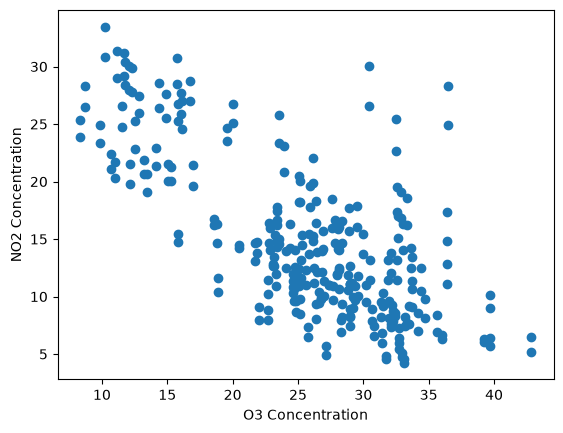

In [90]:
fig, ax = plt.subplots()
ax.scatter(conc_all["O3"], conc_all["NO2"])
ax.set_xlabel("O3 Concentration")
ax.set_ylabel("NO2 Concentration")

plt.show()

ozone and PM

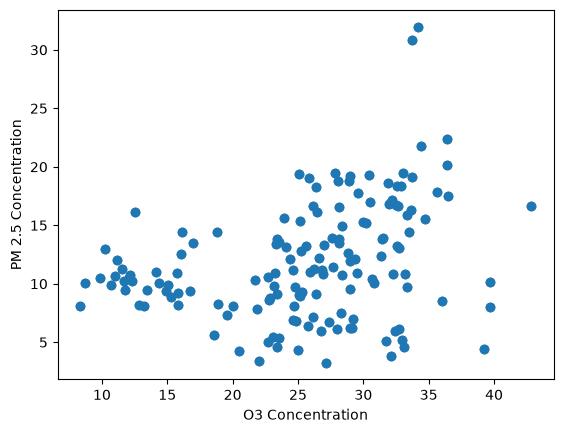

In [93]:
fig, ax = plt.subplots()
ax.scatter(conc_all["O3"], conc_all["PM"])
ax.set_xlabel("O3 Concentration")
ax.set_ylabel("PM 2.5 Concentration")

plt.show()

#1 

In [102]:
xVal = conc_all[["O3", "NO2", "PM"]]
yVal = np.array(conc_all['seasons'])

In [103]:
X_train, X_test, y_train, y_test = train_test_split(xVal,yVal, test_size=0.2)

In [115]:
train_ridge = RidgeClassifier(alpha = 0).fit(X_train, y_train)
train_ridge.score(X_train, y_train)

# I think i messed up earlier in the code because my score does not change with changing the alpha. 
# no matter what value i use i get 0.8423236514522822

0.8423236514522822

#2 I think the cost function being used is MSE with L2 ridge classification

In [124]:
train_ridge0 = RidgeClassifier(alpha = 0).fit(X_train, y_train)
train_ridge0001= RidgeClassifier(alpha = 0.001).fit(X_train, y_train)
train_ridge001= RidgeClassifier(alpha = 0.01).fit(X_train, y_train)

print(train_ridge0.coef_)
print(train_ridge0001.coef_)
print(train_ridge001.coef_)
print(train_ridge0.score(X_train, y_train))
print(train_ridge0001.score(X_train, y_train))
print(train_ridge001.score(X_train, y_train))

[ 0.02842039 -0.05177565  0.0841241 ]
[ 0.0284204  -0.05177563  0.08412408]
[ 0.02842052 -0.05177548  0.08412388]
0.8423236514522822
0.8423236514522822
0.8423236514522822


In [125]:
train_ridge09 = RidgeClassifier(alpha = 0.9).fit(X_train, y_train)
train_ridge1= RidgeClassifier(alpha = 1).fit(X_train, y_train)
print(train_ridge09.coef_)
print(train_ridge1.coef_)

print(train_ridge09.score(X_train, y_train))
print(train_ridge1.score(X_train, y_train))


[ 0.02843223 -0.05176096  0.08410374]
[ 0.02843354 -0.05175933  0.08410148]
0.8423236514522822
0.8423236514522822


In [ ]:
# the optimal ridge penalty would be the one with the highest score. A low alpha value would represent a weaker penalty but a higher alpha would be a stronger penalty
# based on my training data, i chose alphas of 0, 0.001, 0.1 to represent low alpha, weaker penalty, but the score value didnt change. 
# I also chose alphas of 0.9, and 1, and the score didnt change either.

# the optimal value would make my score higher, but it didnt change. 

In [127]:
train_ridge0.score(X_test, y_test)
# I also used all of my training ridgeclassifiers for my test data by swapping out the variables, train_ridge0, train_ridge001,train_ridge1, it doesnt change.  

0.8852459016393442

In [ ]:
# the final model error is 1-score, so that would be around 12% error using this test data from my training. 

In [129]:
X_train2, X_test2, y_train2, y_test2 = train_test_split(xVal,yVal, test_size=0.4)

In [135]:
train_ridge09 = RidgeClassifier(alpha = 0.9).fit(X_train2, y_train2)
print("train score", train_ridge09.score(X_train2, y_train2))
print("test score", train_ridge09.score(X_test2, y_test2))

train score 0.861878453038674
test score 0.8347107438016529


In [ ]:
#6.  I did the same thing of changing my alpha and my score did not change itself, and compared to my previous split, the answers are essentially the same of 0.84 and 0.86 roughly. 

In [137]:
#7. 
from sklearn.linear_model import LogisticRegression
train_log = LogisticRegression().fit(X_train, y_train)
print(train_log.score(X_train, y_train))
print(train_log.score(X_test, y_test))

0.8729281767955801
0.859504132231405


In [138]:
# this shows that both the ridge classification and the logistic regression model are practically the same in performance.
